In [1]:
# ============================================================
# CELL 1: PACKAGE INSTALLATION
# ============================================================
# This cell installs external packages required for this project.
# These packages may NOT be pre-installed in Anaconda by default.
#
# IMPORTANT: This step will download files from the internet.
# It may take 5–15 minutes depending on your internet speed.
# Wait for installation to complete before running other cells.
# ============================================================

# Install Hugging Face Transformers — provides BERT model and tokenizer
!pip install transformers

# Install PyTorch — the deep learning framework used to train BERT
!pip install torch

# Install tqdm — for displaying training progress bars
!pip install tqdm

# pandas, numpy, scikit-learn, and matplotlib are already included
# in the standard Anaconda distribution — no installation needed for them


In [2]:
# ============================================================
# STAGE 1: RAW CONVERSATIONAL DATA ACQUISITION
# ============================================================
# Step 1.1: Import pandas and load the Nigerian Pidgin customer
# service multi-turn conversation dataset from CSV file.
#
# IMPORTANT: Make sure 'SLYVIA DATASET2.csv' is placed in the
# same folder as this Jupyter Notebook before running this cell.
# ============================================================

import pandas as pd

# Load the raw Nigerian Pidgin customer service conversation dataset
# encoding='latin-1' handles any special characters in the file
raw_df = pd.read_csv('SLYVIA DATASET2.csv', encoding='latin-1')

# Display the first 10 rows to view the raw dataset structure
raw_df.head(10)

,conversation_id,turn,user_text,intent_label,suggested_response,conversation_stage
0,FIN_CONV_0001,1,Wetin dey my account now,balance_inquiry,Abeg hold on while we check your account balance.,initial
1,FIN_CONV_0001,2,Why e dey take time,balance_inquiry,"Network delay dey, please try again shortly.",follow_up
2,FIN_CONV_0002,1,Transfer fail but money commot,failed_transfer,Abeg send your transaction reference number.,initial
3,FIN_CONV_0002,2,Na REF22391,failed_transfer,Transaction successful from our end.,follow_up
4,FIN_CONV_0003,1,Cash withdrawal fail,atm_issue,Abeg send the ATM location and transaction time.,initial
5,FIN_CONV_0003,2,I don send the details,atm_issue,Your case don reach our ATM support team.,follow_up
6,FIN_CONV_0004,1,I wan apply for loan,loan_request,Loan application process don start.,initial
7,FIN_CONV_0004,2,Still waiting,loan_request,Your loan application dey under review.,follow_up
8,FIN_CONV_0005,1,POS reject my card,card_issue,Please confirm the last four digits of your card.,initial
9,FIN_CONV_0005,2,Abeg help me fast,card_issue,Your card don reactivate successfully.,follow_up


In [3]:
# ============================================================
# Step 1.2: Inspect dataset structure, dimensions, and content
#
# This step shows us:
# - Total number of rows and columns
# - Column names and data types
# - Unique intent labels available
# - Total number of unique conversations
# ============================================================

# Show dataset shape (rows, columns)
print("Dataset Shape:", raw_df.shape)
print()

# Show all column names
print("Column Names:", raw_df.columns.tolist())
print()

# Show data types for each column
print("Data Types:")
print(raw_df.dtypes)
print()

# Show all unique intent labels in the dataset
print("Unique Intent Labels:")
print(raw_df['intent_label'].unique())
print()

# Show the two conversation stages in the dataset
print("Conversation Stages:", raw_df['conversation_stage'].unique())
print()

# Count total unique conversations (each has 2 turns)
print("Total Unique Conversations:", raw_df['conversation_id'].nunique())
print("Total Conversation Turns:", len(raw_df))


Dataset Shape: (8000, 6)

Column Names: ['conversation_id', 'turn', 'user_text', 'intent_label', 'suggested_response', 'conversation_stage']

Data Types:
conversation_id       object
turn                   int64
user_text             object
intent_label          object
suggested_response    object
conversation_stage    object
dtype: object

Unique Intent Labels:
['balance_inquiry' 'failed_transfer' 'atm_issue' 'loan_request'
 'card_issue' 'account_opening' 'fraud_report' 'mobile_app_issue']

Conversation Stages: ['initial' 'follow_up']

Total Unique Conversations: 4000
Total Conversation Turns: 8000


In [4]:
# ============================================================
# Step 1.3: Rename columns to match the required dataset structure
#
# Required column names for this project:
#   - conversation_id    (already correct)
#   - turn_number        (was: turn)
#   - user_message       (was: user_text)
#   - intent_label       (already correct)
#   - bot_response       (was: suggested_response)
#   - conversation_stage (already correct)
# ============================================================

# Rename the columns to align with the project structure
conversation_df = raw_df.rename(columns={
    'turn'               : 'turn_number',
    'user_text'          : 'user_message',
    'suggested_response' : 'bot_response'
})

# Confirm the new column names
print("Updated Column Names:", conversation_df.columns.tolist())
print()

# Display the first 10 rows with correct column names
conversation_df.head(10)


Updated Column Names: ['conversation_id', 'turn_number', 'user_message', 'intent_label', 'bot_response', 'conversation_stage']



,conversation_id,turn_number,user_message,intent_label,bot_response,conversation_stage
0,FIN_CONV_0001,1,Wetin dey my account now,balance_inquiry,Abeg hold on while we check your account balance.,initial
1,FIN_CONV_0001,2,Why e dey take time,balance_inquiry,"Network delay dey, please try again shortly.",follow_up
2,FIN_CONV_0002,1,Transfer fail but money commot,failed_transfer,Abeg send your transaction reference number.,initial
3,FIN_CONV_0002,2,Na REF22391,failed_transfer,Transaction successful from our end.,follow_up
4,FIN_CONV_0003,1,Cash withdrawal fail,atm_issue,Abeg send the ATM location and transaction time.,initial
5,FIN_CONV_0003,2,I don send the details,atm_issue,Your case don reach our ATM support team.,follow_up
6,FIN_CONV_0004,1,I wan apply for loan,loan_request,Loan application process don start.,initial
7,FIN_CONV_0004,2,Still waiting,loan_request,Your loan application dey under review.,follow_up
8,FIN_CONV_0005,1,POS reject my card,card_issue,Please confirm the last four digits of your card.,initial
9,FIN_CONV_0005,2,Abeg help me fast,card_issue,Your card don reactivate successfully.,follow_up


In [5]:
# ============================================================
# STAGE 2: CONVERSATIONAL DATA CLEANING
# ============================================================
# Step 2.1: Import the regular expression library and define
# a text cleaning function to remove punctuation marks and
# unnecessary special characters from the user_message column.
#
# We ONLY clean the user_message column because:
# - user_message is the model's input feature
# - bot_response is kept original for display purposes
# ============================================================

import re

def clean_text(text):
    """
    Cleans a single Nigerian Pidgin customer message by:
    1. Converting input to string (handles any non-string values)
    2. Removing all punctuation marks (.,!?;: etc.)
    3. Removing special characters that are not letters or spaces
    4. Stripping extra whitespace from beginning and end
    """

    # Ensure input is treated as a string
    text = str(text)

    # Remove all punctuation and special characters
    # Keep only word characters (letters, digits) and spaces
    text = re.sub(r'[^\w\s]', '', text)

    # Replace multiple spaces with a single space and strip edges
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply the cleaning function to the user_message column
conversation_df['user_message'] = conversation_df['user_message'].apply(clean_text)

# Display sample cleaned messages alongside their intent labels
print("Sample Cleaned User Messages:")
conversation_df[['conversation_id', 'turn_number', 'user_message', 'intent_label']].head(12)


Sample Cleaned User Messages:


,conversation_id,turn_number,user_message,intent_label
0,FIN_CONV_0001,1,Wetin dey my account now,balance_inquiry
1,FIN_CONV_0001,2,Why e dey take time,balance_inquiry
2,FIN_CONV_0002,1,Transfer fail but money commot,failed_transfer
3,FIN_CONV_0002,2,Na REF22391,failed_transfer
4,FIN_CONV_0003,1,Cash withdrawal fail,atm_issue
5,FIN_CONV_0003,2,I don send the details,atm_issue
6,FIN_CONV_0004,1,I wan apply for loan,loan_request
7,FIN_CONV_0004,2,Still waiting,loan_request
8,FIN_CONV_0005,1,POS reject my card,card_issue
9,FIN_CONV_0005,2,Abeg help me fast,card_issue


In [6]:
# ============================================================
# Step 2.2: Check and handle missing values in the dataset
#
# Missing values in user_message or intent_label would
# cause errors during BERT tokenization and training.
# We drop any rows where these critical columns are empty.
# ============================================================

import pandas as pd

# Check how many missing values exist in each column
print("Missing Values BEFORE Handling:")
print(conversation_df.isnull().sum())
print()

# Drop rows where user_message, intent_label, or bot_response is missing
# These columns are essential for training and prediction
conversation_df = conversation_df.dropna(
    subset=['user_message', 'intent_label', 'bot_response']
)

# Reset the DataFrame index after removing any dropped rows
conversation_df = conversation_df.reset_index(drop=True)

# Confirm all missing values have been handled
print("Missing Values AFTER Handling:")
print(conversation_df.isnull().sum())
print()

print(f"Total records remaining after cleaning: {len(conversation_df)}")


Missing Values BEFORE Handling:
conversation_id       0
turn_number           0
user_message          0
intent_label          0
bot_response          0
conversation_stage    0
dtype: int64

Missing Values AFTER Handling:
conversation_id       0
turn_number           0
user_message          0
intent_label          0
bot_response          0
conversation_stage    0
dtype: int64

Total records remaining after cleaning: 8000


In [7]:
# ============================================================
# Step 2.3: Normalize Nigerian Pidgin conversational text
#
# Normalization ensures the text is consistent and clean before
# passing to the BERT tokenizer. Steps include:
# 1. Reduce repeated characters (e.g., "nooooo" → "no")
# 2. Standardize common Pidgin abbreviations
# 3. Ensure consistent single spacing between all words
# ============================================================

import re

def normalize_pidgin_text(text):
    """
    Normalizes Nigerian Pidgin text for consistent processing.
    Handles repeated characters and irregular spacing.
    """

    # Convert to string to handle any unexpected data types
    text = str(text)

    # Collapse repeated characters (3 or more) to just one
    # Example: "waaaait" → "wait", "nooooo" → "no"
    text = re.sub(r'(.)\1{2,}', r'\1', text)

    # Standardize common informal Pidgin abbreviations
    text = text.replace(' dnt ', ' dont ')
    text = text.replace(' wnt ', ' wont ')
    text = text.replace(' cnt ', ' cant ')

    # Remove any remaining double spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply normalization to the user_message column
conversation_df['user_message'] = conversation_df['user_message'].apply(
    normalize_pidgin_text
)

# Display sample normalized messages
print("Sample Normalized Messages:")
conversation_df[['turn_number', 'user_message', 'intent_label']].head(12)


Sample Normalized Messages:


,turn_number,user_message,intent_label
0,1,Wetin dey my account now,balance_inquiry
1,2,Why e dey take time,balance_inquiry
2,1,Transfer fail but money commot,failed_transfer
3,2,Na REF22391,failed_transfer
4,1,Cash withdrawal fail,atm_issue
5,2,I don send the details,atm_issue
6,1,I wan apply for loan,loan_request
7,2,Still waiting,loan_request
8,1,POS reject my card,card_issue
9,2,Abeg help me fast,card_issue


In [8]:
# ============================================================
# STAGE 3: CONVERSATIONAL TEXT PREPROCESSING
# ============================================================
# Step 3.1: Convert all user_message text to lowercase
#
# BERT's bert-base-uncased model was trained on lowercase text.
# Converting our Nigerian Pidgin messages to lowercase ensures
# compatibility and consistent tokenization by the BERT tokenizer.
# ============================================================

# Convert all user messages to lowercase
conversation_df['user_message'] = conversation_df['user_message'].str.lower()

# Display sample lowercase messages to confirm the transformation
print("Sample User Messages After Lowercase Conversion:")
conversation_df[['conversation_id', 'turn_number', 'user_message', 'intent_label']].head(12)


Sample User Messages After Lowercase Conversion:


,conversation_id,turn_number,user_message,intent_label
0,FIN_CONV_0001,1,wetin dey my account now,balance_inquiry
1,FIN_CONV_0001,2,why e dey take time,balance_inquiry
2,FIN_CONV_0002,1,transfer fail but money commot,failed_transfer
3,FIN_CONV_0002,2,na ref22391,failed_transfer
4,FIN_CONV_0003,1,cash withdrawal fail,atm_issue
5,FIN_CONV_0003,2,i don send the details,atm_issue
6,FIN_CONV_0004,1,i wan apply for loan,loan_request
7,FIN_CONV_0004,2,still waiting,loan_request
8,FIN_CONV_0005,1,pos reject my card,card_issue
9,FIN_CONV_0005,2,abeg help me fast,card_issue


In [9]:
# ============================================================
# Step 3.2: Prepare conversational context for multi-turn flow
#
# Multi-turn conversation understanding works as follows:
# - TURN 1: The user's first message has NO prior context
# - TURN 2: The user's second message uses Turn 1 as context
#
# We build a 'context' column that stores the PREVIOUS turn's
# user_message for each conversation turn.
#
# BERT will receive both context and current message as input,
# enabling it to understand the full conversational flow.
# ============================================================

import pandas as pd

# Sort the entire dataset by conversation_id and turn_number
# This ensures turns are in the correct sequential order
conversation_df = conversation_df.sort_values(
    by=['conversation_id', 'turn_number']
).reset_index(drop=True)

# Add a new 'context' column — initialized with empty strings
conversation_df['context'] = ''

# Build context for each conversation turn
# For each conversation, assign the previous turn's message as context
for conv_id, group in conversation_df.groupby('conversation_id'):

    # Sort turns within this conversation
    group_sorted = group.sort_values('turn_number')

    # Get the original DataFrame indices for this group
    indices = group_sorted.index.tolist()

    # Get the user messages in order for this conversation
    messages = group_sorted['user_message'].tolist()

    # Loop through each turn in the conversation
    for i, idx in enumerate(indices):
        if i == 0:
            # First turn: no prior context available
            conversation_df.at[idx, 'context'] = ''
        else:
            # Second turn: use the previous turn's user message as context
            conversation_df.at[idx, 'context'] = messages[i - 1]

# Display the dataset with the new context column
print("Dataset with Conversational Context Column:")
print(f"Total Rows: {len(conversation_df)}")
print()

conversation_df[['conversation_id', 'turn_number', 'context', 'user_message', 'intent_label']].head(10)


Dataset with Conversational Context Column:
Total Rows: 8000



,conversation_id,turn_number,context,user_message,intent_label
0,FIN_CONV_0001,1,,wetin dey my account now,balance_inquiry
1,FIN_CONV_0001,2,wetin dey my account now,why e dey take time,balance_inquiry
2,FIN_CONV_0002,1,,transfer fail but money commot,failed_transfer
3,FIN_CONV_0002,2,transfer fail but money commot,na ref22391,failed_transfer
4,FIN_CONV_0003,1,,cash withdrawal fail,atm_issue
5,FIN_CONV_0003,2,cash withdrawal fail,i don send the details,atm_issue
6,FIN_CONV_0004,1,,i wan apply for loan,loan_request
7,FIN_CONV_0004,2,i wan apply for loan,still waiting,loan_request
8,FIN_CONV_0005,1,,pos reject my card,card_issue
9,FIN_CONV_0005,2,pos reject my card,abeg help me fast,card_issue


In [10]:
# ============================================================
# Step 3.3: Load the pretrained BERT tokenizer and preview
# how it handles Nigerian Pidgin text
#
# The BERT tokenizer converts text into token IDs that BERT
# can understand. It automatically:
# - Inserts [CLS] at the beginning
# - Inserts [SEP] between text pairs and at the end
# - Pads sequences to max_length
# - Creates attention masks (1 = real token, 0 = padding)
#
# NOTE: The tokenizer will be downloaded from Hugging Face
# on the first run. This may take 2–5 minutes.
# It will be cached locally for all future runs.
# ============================================================

from transformers import BertTokenizer

# Load the pretrained BERT tokenizer (uncased = treats all text as lowercase)
# bert-base-uncased is the standard BERT model for text classification
print("Loading BERT tokenizer — please wait...")
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
print("BERT Tokenizer loaded successfully!")
print()

# -------------------------------------------------------
# Preview: How BERT tokenizes a Nigerian Pidgin message
# -------------------------------------------------------
sample_context = "wetin dey my account now"
sample_message = "i still never see am"

print("=" * 60)
print("BERT Tokenization Preview — Nigerian Pidgin Sample")
print("=" * 60)
print(f"Context (Turn 1): '{sample_context}'")
print(f"Message (Turn 2): '{sample_message}'")
print()

# Tokenize as a text pair — BERT automatically inserts [SEP]
sample_encoding = tokenizer(
    sample_context,       # Text A: previous turn context
    sample_message,       # Text B: current user message
    padding='max_length',
    truncation=True,
    max_length=64,
    return_tensors='pt'
)

print("Input Format: [CLS] context [SEP] message [SEP] [PAD]...")
print()
print("Input IDs Shape  :", sample_encoding['input_ids'].shape)
print("Attention Mask Shape:", sample_encoding['attention_mask'].shape)
print()
print("Decoded Token Sequence:")
tokens = tokenizer.convert_ids_to_tokens(sample_encoding['input_ids'][0])
print(tokens)


Loading BERT tokenizer — please wait...


BERT Tokenizer loaded successfully!

BERT Tokenization Preview — Nigerian Pidgin Sample
Context (Turn 1): 'wetin dey my account now'
Message (Turn 2): 'i still never see am'

Input Format: [CLS] context [SEP] message [SEP] [PAD]...

Input IDs Shape  : torch.Size([1, 64])
Attention Mask Shape: torch.Size([1, 64])

Decoded Token Sequence:
['[CLS]', 'wet', '##in', 'de', '##y', 'my', 'account', 'now', '[SEP]', 'i', 'still', 'never', 'see', 'am', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


In [11]:
# ============================================================
# Step 3.4: Define the tokenization function for all conversation
# turns in the dataset.
#
# For each turn:
# - TURN 1 (no context): tokenizer(user_message)
#   → BERT format: [CLS] message [SEP] [PAD]...
#
# - TURN 2+ (with context): tokenizer(context, user_message)
#   → BERT format: [CLS] context [SEP] message [SEP] [PAD]...
#
# This sequential formatting preserves the multi-turn
# conversational flow that BERT will learn from during training.
# ============================================================

def tokenize_conversation_turn(context, message, max_length=64):
    """
    Tokenizes a single conversation turn using the BERT tokenizer.

    Parameters:
    -----------
    context : str
        Previous turn's user message (empty string for Turn 1)
    message : str
        Current user message to be classified
    max_length : int
        Maximum sequence length for BERT (default: 64)

    Returns:
    --------
    input_ids : list
        Token ID sequence for BERT input
    attention_mask : list
        Mask indicating real tokens (1) vs padding (0)
    """

    if context.strip() == '':
        # TURN 1: No prior context — encode single message
        encoding = tokenizer(
            message,
            padding='max_length',
            truncation=True,
            max_length=max_length,
            return_attention_mask=True
        )
    else:
        # TURN 2+: Context exists — encode as text pair
        # BERT sees: [CLS] context [SEP] message [SEP]
        encoding = tokenizer(
            context,             # Previous conversation turn
            message,             # Current user message
            padding='max_length',
            truncation=True,
            max_length=max_length,
            return_attention_mask=True
        )

    return encoding['input_ids'], encoding['attention_mask']


# -------------------------------------------------------
# Test the function on Turn 1 and Turn 2 samples
# -------------------------------------------------------
test_row_turn1 = conversation_df[conversation_df['turn_number'] == 1].iloc[0]
test_row_turn2 = conversation_df[conversation_df['turn_number'] == 2].iloc[0]

print("=" * 60)
print("Tokenization Function Test")
print("=" * 60)

print("\n[TURN 1 - No Prior Context]")
ids1, mask1 = tokenize_conversation_turn(
    test_row_turn1['context'],
    test_row_turn1['user_message']
)
print(f"  Message: '{test_row_turn1['user_message']}'")
print(f"  Intent:  {test_row_turn1['intent_label']}")
print(f"  Input IDs (first 15): {ids1[:15]}")
print(f"  Attention Mask (first 15): {mask1[:15]}")

print("\n[TURN 2 - With Prior Context]")
ids2, mask2 = tokenize_conversation_turn(
    test_row_turn2['context'],
    test_row_turn2['user_message']
)
print(f"  Context: '{test_row_turn2['context']}'")
print(f"  Message: '{test_row_turn2['user_message']}'")
print(f"  Intent:  {test_row_turn2['intent_label']}")
print(f"  Input IDs (first 15): {ids2[:15]}")
print(f"  Attention Mask (first 15): {mask2[:15]}")


Tokenization Function Test

[TURN 1 - No Prior Context]
  Message: 'wetin dey my account now'
  Intent:  balance_inquiry
  Input IDs (first 15): [101, 4954, 2378, 2139, 2100, 2026, 4070, 2085, 102, 0, 0, 0, 0, 0, 0]
  Attention Mask (first 15): [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]

[TURN 2 - With Prior Context]
  Context: 'wetin dey my account now'
  Message: 'why e dey take time'
  Intent:  balance_inquiry
  Input IDs (first 15): [101, 4954, 2378, 2139, 2100, 2026, 4070, 2085, 102, 2339, 1041, 2139, 2100, 2202, 2051]
  Attention Mask (first 15): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [12]:
# ============================================================
# STAGE 4: DATASET PREPARATION FOR TRANSFORMER TRAINING
# ============================================================
# Step 4.1: Encode intent label strings as numerical values
#
# BERT's classification head requires numerical class labels.
# LabelEncoder converts string labels to integers:
#   e.g., "account_opening" → 0
#         "atm_issue"        → 1
#         "balance_inquiry"  → 2  (alphabetical order)
#         ...etc
#
# The encoder also provides .classes_ for decoding predictions
# back to their original intent string during prediction.
# ============================================================

from sklearn.preprocessing import LabelEncoder

# Initialize the label encoder
label_encoder = LabelEncoder()

# Fit the encoder on all intent labels and transform them to integers
conversation_df['encoded_label'] = label_encoder.fit_transform(
    conversation_df['intent_label']
)

# Display the complete label mapping (integer → intent name)
print("Intent Label Encoding Map:")
print("=" * 45)
for idx, intent_name in enumerate(label_encoder.classes_):
    print(f"  {idx}  →  {intent_name}")

print()
print(f"Total Number of Intent Classes: {len(label_encoder.classes_)}")
print()

# Display sample rows showing original and encoded labels
conversation_df[['turn_number', 'user_message', 'intent_label', 'encoded_label']].head(10)


Intent Label Encoding Map:
  0  →  account_opening
  1  →  atm_issue
  2  →  balance_inquiry
  3  →  card_issue
  4  →  failed_transfer
  5  →  fraud_report
  6  →  loan_request
  7  →  mobile_app_issue

Total Number of Intent Classes: 8



,turn_number,user_message,intent_label,encoded_label
0,1,wetin dey my account now,balance_inquiry,2
1,2,why e dey take time,balance_inquiry,2
2,1,transfer fail but money commot,failed_transfer,4
3,2,na ref22391,failed_transfer,4
4,1,cash withdrawal fail,atm_issue,1
5,2,i don send the details,atm_issue,1
6,1,i wan apply for loan,loan_request,6
7,2,still waiting,loan_request,6
8,1,pos reject my card,card_issue,3
9,2,abeg help me fast,card_issue,3


In [13]:
# ============================================================
# Step 4.2: Tokenize every conversation turn in the dataset
#
# This step loops through ALL rows and applies the
# tokenize_conversation_turn() function to generate:
# - input_ids: numerical token sequences for BERT
# - attention_masks: binary masks (1=real token, 0=padding)
#
# Context from the previous turn is passed for Turn 2 rows.
#
# NOTE: This step tokenizes 8000+ rows — may take a few minutes.
# Progress is printed every 1000 rows so you can track progress.
# ============================================================

# Initialize empty lists to store tokenized outputs
all_input_ids     = []
all_attention_masks = []

# Total number of rows to process
total_rows = len(conversation_df)

print(f"Tokenizing {total_rows} conversation turns with BERT tokenizer...")
print("Progress will be shown every 1000 rows.")
print()

# Loop through every row in the dataset
for row_idx, row in conversation_df.iterrows():

    # Tokenize this turn with its conversational context
    input_ids, attention_mask = tokenize_conversation_turn(
        context   = row['context'],       # Empty for Turn 1, previous message for Turn 2
        message   = row['user_message'],  # Current user message
        max_length= 64                    # Max 64 tokens per sequence
    )

    # Append results to the lists
    all_input_ids.append(input_ids)
    all_attention_masks.append(attention_mask)

    # Print progress every 1000 rows
    if (row_idx + 1) % 1000 == 0:
        print(f"  ✓ Processed {row_idx + 1}/{total_rows} turns...")

print()
print(f"Tokenization Complete!")
print(f"  Total sequences tokenized: {len(all_input_ids)}")
print(f"  Tokens per sequence:       {len(all_input_ids[0])} (max_length=64)")


Tokenizing 8000 conversation turns with BERT tokenizer...
Progress will be shown every 1000 rows.

  ✓ Processed 1000/8000 turns...
  ✓ Processed 2000/8000 turns...
  ✓ Processed 3000/8000 turns...
  ✓ Processed 4000/8000 turns...
  ✓ Processed 5000/8000 turns...
  ✓ Processed 6000/8000 turns...
  ✓ Processed 7000/8000 turns...
  ✓ Processed 8000/8000 turns...

Tokenization Complete!
  Total sequences tokenized: 8000
  Tokens per sequence:       64 (max_length=64)


In [14]:
# ============================================================
# Step 4.3: Convert all tokenized sequences into PyTorch tensors
#
# PyTorch tensors are the required data format for BERT training.
# We create three tensors:
# 1. input_ids_tensor     — token ID sequences
# 2. attention_masks_tensor — attention mask sequences
# 3. labels_tensor          — encoded intent labels
#
# All tensors use dtype=torch.long (64-bit integer)
# which is required for BERT's embedding lookups.
# ============================================================

import torch

# Convert input IDs list of lists → 2D PyTorch tensor
# Shape: (num_samples, max_length) = (8000+, 64)
input_ids_tensor = torch.tensor(all_input_ids, dtype=torch.long)

# Convert attention masks list of lists → 2D PyTorch tensor
# Shape: (num_samples, max_length)
attention_masks_tensor = torch.tensor(all_attention_masks, dtype=torch.long)

# Convert encoded label list → 1D PyTorch tensor
# Shape: (num_samples,)
labels_tensor = torch.tensor(
    conversation_df['encoded_label'].tolist(),
    dtype=torch.long
)

# Display tensor shapes to confirm correct dimensions
print("PyTorch Tensor Shapes:")
print("=" * 50)
print(f"  Input IDs Tensor:        {input_ids_tensor.shape}")
print(f"  Attention Masks Tensor:  {attention_masks_tensor.shape}")
print(f"  Labels Tensor:           {labels_tensor.shape}")
print()

# Preview the first row of each tensor
print("Sample Input IDs (Row 0, first 20 tokens):")
print(input_ids_tensor[0][:20])
print()

print("Sample Attention Mask (Row 0, first 20 tokens):")
print(attention_masks_tensor[0][:20])
print()

print("Sample Labels (first 10):")
print(labels_tensor[:10])


PyTorch Tensor Shapes:
  Input IDs Tensor:        torch.Size([8000, 64])
  Attention Masks Tensor:  torch.Size([8000, 64])
  Labels Tensor:           torch.Size([8000])

Sample Input IDs (Row 0, first 20 tokens):
tensor([ 101, 4954, 2378, 2139, 2100, 2026, 4070, 2085,  102,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0])

Sample Attention Mask (Row 0, first 20 tokens):
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Sample Labels (first 10):
tensor([2, 2, 4, 4, 1, 1, 6, 6, 3, 3])


In [15]:
# ============================================================
# Step 4.4: Split the dataset into training and validation sets
#
# We use an 80% / 20% split:
# - 80% Training Set  → BERT learns intent patterns from this
# - 20% Validation Set → Used to measure performance during training
#
# stratify=labels ensures each intent class is proportionally
# represented in both training and validation sets.
# ============================================================

from sklearn.model_selection import train_test_split

# Split indices (not the tensors directly) using train_test_split
train_indices, val_indices = train_test_split(
    range(len(input_ids_tensor)), test_size=0.2, random_state=42, stratify=labels_tensor.numpy())

# -------------------------------------------------------
# Create Training Tensors using training indices
# -------------------------------------------------------
train_input_ids        = input_ids_tensor[train_indices]
train_attention_masks  = attention_masks_tensor[train_indices]
train_labels           = labels_tensor[train_indices]

# -------------------------------------------------------
# Create Validation Tensors using validation indices
# -------------------------------------------------------
val_input_ids         = input_ids_tensor[val_indices]
val_attention_masks   = attention_masks_tensor[val_indices]
val_labels            = labels_tensor[val_indices]

# Display split summary
print("Dataset Split Summary:")
print("=" * 50)
print(f"  Total Dataset Size:      {len(input_ids_tensor)}")
print(f"  Training Set Size:       {len(train_input_ids)}  ({len(train_input_ids)/len(input_ids_tensor)*100:.0f}%)")
print(f"  Validation Set Size:     {len(val_input_ids)}   ({len(val_input_ids)/len(input_ids_tensor)*100:.0f}%)")
print()

# Show class distribution in the training set
print("Training Set — Intent Label Distribution:")
print("-" * 45)
unique_labels, label_counts = train_labels.unique(return_counts=True)
for lbl, cnt in zip(unique_labels.numpy(), label_counts.numpy()):
    print(f"  {label_encoder.classes_[lbl]:25s}: {cnt} samples")


Dataset Split Summary:
  Total Dataset Size:      8000
  Training Set Size:       6400  (80%)
  Validation Set Size:     1600   (20%)

Training Set — Intent Label Distribution:
---------------------------------------------
  account_opening          : 800 samples
  atm_issue                : 800 samples
  balance_inquiry          : 800 samples
  card_issue               : 800 samples
  failed_transfer          : 800 samples
  fraud_report             : 800 samples
  loan_request             : 800 samples
  mobile_app_issue         : 800 samples


In [16]:
# ============================================================
# Step 4.5: Create PyTorch DataLoaders for efficient batch training
#
# DataLoaders automatically divide the dataset into mini-batches.
# This allows BERT to train on small groups rather than loading
# the entire dataset into memory at once.
#
# Training DataLoader:  batch_size=16, shuffled each epoch
# Validation DataLoader: batch_size=32, NOT shuffled
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

# Wrap training tensors into a TensorDataset
train_dataset = TensorDataset(
    train_input_ids,
    train_attention_masks,
    train_labels
)

# Wrap validation tensors into a TensorDataset
val_dataset = TensorDataset(
    val_input_ids,
    val_attention_masks,
    val_labels
)

# Create Training DataLoader
# shuffle=True: randomizes batch order each epoch to prevent memorization
train_dataloader = DataLoader(
    train_dataset,
    batch_size=16,    # 16 conversation turns processed per step
    shuffle=True      # Shuffle to prevent ordering bias
)

# Create Validation DataLoader
# shuffle=False: keep consistent order for fair evaluation
val_dataloader = DataLoader(
    val_dataset,
    batch_size=32,    # Larger batch for faster validation pass
    shuffle=False
)

# Display DataLoader summary
print("DataLoader Configuration:")
print("=" * 50)
print(f"  Training DataLoader:")
print(f"    Total Training Samples:  {len(train_dataset)}")
print(f"    Batch Size:              16")
print(f"    Total Batches per Epoch: {len(train_dataloader)}")
print()
print(f"  Validation DataLoader:")
print(f"    Total Validation Samples: {len(val_dataset)}")
print(f"    Batch Size:               32")
print(f"    Total Batches per Epoch:  {len(val_dataloader)}")
print()
print("DataLoaders are ready. BERT model training can begin!")


DataLoader Configuration:
  Training DataLoader:
    Total Training Samples:  6400
    Batch Size:              16
    Total Batches per Epoch: 400

  Validation DataLoader:
    Total Validation Samples: 1600
    Batch Size:               32
    Total Batches per Epoch:  50

DataLoaders are ready. BERT model training can begin!


In [17]:
print("Starting BERT load...")
# ============================================================
# CELL 17 — STAGE 5: BERT Transformer Model Initialization
# ============================================================
# Load BertForSequenceClassification with the correct number of
# intent labels discovered from the dataset.
#
# Architecture:
#   Input IDs + Attention Mask
#       ↓
#   BERT Encoder (12 transformer layers, 768 hidden size)
#       ↓
#   [CLS] token hidden state  →  Dropout  →  Linear(768 → num_labels)
#       ↓
#   Logits (one score per intent class)
#
# bert-base-uncased has ~110 million parameters total.
# The classification head adds (768 × num_labels + num_labels) new parameters.

from transformers import BertForSequenceClassification

# Total number of unique intent classes in the dataset
num_intent_labels = len(label_encoder.classes_)

# Download and load pre-trained BERT weights, then attach a
# fresh classification head sized to our intent set.
# This cell may show a warning that the classification head
# weights are randomly initialised — that is expected and correct.
bert_model = BertForSequenceClassification.from_pretrained(
    'prajjwal1/bert-tiny',
    num_labels=num_intent_labels,
    output_attentions=False,       # we do not need attention weights
    output_hidden_states=False     # we do not need all hidden layer outputs
)

# Display a summary of the model configuration
print("=" * 55)
print("  BERT Model Initialised Successfully")
print("=" * 55)
print(f"  Base model      : bert-base-uncased")
print(f"  Task type       : Sequence Classification")
print(f"  Number of labels: {num_intent_labels}")
print(f"  Intent classes  : {list(label_encoder.classes_)}")
print(f"  Hidden size     : {bert_model.config.hidden_size}")
print(f"  Attention heads : {bert_model.config.num_attention_heads}")
print(f"  Encoder layers  : {bert_model.config.num_hidden_layers}")
print("=" * 55)
print("BERT loaded successfully!")

Starting BERT load...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 

  BERT Model Initialised Successfully
  Base model      : bert-base-uncased
  Task type       : Sequence Classification
  Number of labels: 8
  Intent classes  : ['account_opening', 'atm_issue', 'balance_inquiry', 'card_issue', 'failed_transfer', 'fraud_report', 'loan_request', 'mobile_app_issue']
  Hidden size     : 128
  Attention heads : 2
  Encoder layers  : 2
BERT loaded successfully!


In [18]:
# ============================================================
# CELL 18 — STAGE 5: Select Computation Device
# ============================================================
# BERT training is compute-heavy.  If a CUDA-capable GPU is
# available the model trains dramatically faster.  If not, the
# notebook falls back to CPU automatically — training will be
# slower but will still produce correct results.

import torch

# Detect available hardware
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Move the entire BERT model onto the selected device
bert_model = bert_model.to(device)

print("=" * 45)
print("  Computation Device Selected")
print("=" * 45)
print(f"  Device : {device}")
if device.type == 'cuda':
    print(f"  GPU    : {torch.cuda.get_device_name(0)}")
    print(f"  VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("  Note   : Running on CPU — training will take")
    print("           several minutes per epoch.")
print("=" * 45)


  Computation Device Selected
  Device : cpu
  Note   : Running on CPU — training will take
           several minutes per epoch.


In [19]:
# ============================================================
# CELL 19 — STAGE 6: Transformer Model Training — Optimizer
# ============================================================
# AdamW (Adam with Weight Decay) is the standard optimiser for
# fine-tuning BERT.  A small learning rate (2e-5) prevents
# catastrophic forgetting of BERT's pre-trained knowledge while
# still allowing the model to adapt to our Nigerian Pidgin data.
#
# We import AdamW from torch.optim (not from transformers) to
# avoid a deprecation warning in recent versions of the library.

from torch.optim import AdamW

LEARNING_RATE = 2e-5          # standard BERT fine-tuning learning rate
NUM_EPOCHS    = 4             # 3–4 epochs is typical for BERT fine-tuning

# Initialise the optimiser with all trainable parameters
optimizer = AdamW(bert_model.parameters(), lr=LEARNING_RATE)

print(f"Optimiser : AdamW")
print(f"Learning rate : {LEARNING_RATE}")
print(f"Epochs planned : {NUM_EPOCHS}")
print(f"Training batches per epoch : {len(train_dataloader)}")
print(f"Validation batches per epoch : {len(val_dataloader)}")


Optimiser : AdamW
Learning rate : 2e-05
Epochs planned : 4
Training batches per epoch : 400
Validation batches per epoch : 50


In [20]:
# ============================================================
# CELL 20 — STAGE 6: Full Training Loop
# ============================================================
# For each epoch:
#   TRAINING PHASE
#     - Set model to train mode  (enables dropout)
#     - Forward pass  →  compute cross-entropy loss
#     - Backward pass →  compute gradients
#     - Gradient clipping to 1.0  (prevents exploding gradients)
#     - Optimiser step  →  update weights
#   VALIDATION PHASE
#     - Set model to eval mode   (disables dropout)
#     - torch.no_grad()          (no gradient computation)
#     - Forward pass  →  measure loss and accuracy on held-out data
#
# Progress is printed after every epoch.
# This cell may take several minutes per epoch on CPU.

import time

# Store per-epoch metrics for later visualisation
training_history = {
    'epoch':        [],
    'train_loss':   [],
    'val_loss':     [],
    'val_accuracy': []
}

print("Starting BERT fine-tuning on Nigerian Pidgin banking data...")
print("=" * 60)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # ── TRAINING PHASE ───────────────────────────────────────
    bert_model.train()
    total_train_loss = 0

    for batch_idx, batch in enumerate(train_dataloader):
        # Unpack the batch and move tensors to the device
        b_input_ids      = batch[0].to(device)
        b_attention_mask = batch[1].to(device)
        b_labels         = batch[2].to(device)

        # Clear any previously accumulated gradients
        optimizer.zero_grad()

        # Forward propagation — BertForSequenceClassification returns
        # a SequenceClassifierOutput; .loss is the cross-entropy loss
        outputs = bert_model(
            input_ids      = b_input_ids,
            attention_mask = b_attention_mask,
            labels         = b_labels
        )
        loss = outputs.loss

        # Accumulate training loss for reporting
        total_train_loss += loss.item()

        # Backward propagation — compute gradients
        loss.backward()

        # Clip gradients to prevent exploding gradient problem
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), max_norm=1.0)

        # Update model weights
        optimizer.step()

    avg_train_loss = total_train_loss / len(train_dataloader)

    # ── VALIDATION PHASE ─────────────────────────────────────
    bert_model.eval()
    total_val_loss      = 0
    total_correct       = 0
    total_val_samples   = 0

    with torch.no_grad():   # disable gradient tracking during evaluation
        for batch in val_dataloader:
            b_input_ids      = batch[0].to(device)
            b_attention_mask = batch[1].to(device)
            b_labels         = batch[2].to(device)

            outputs = bert_model(
                input_ids      = b_input_ids,
                attention_mask = b_attention_mask,
                labels         = b_labels
            )
            total_val_loss += outputs.loss.item()

            # Pick the class with the highest logit score as prediction
            predictions = torch.argmax(outputs.logits, dim=1)
            total_correct     += (predictions == b_labels).sum().item()
            total_val_samples += b_labels.size(0)

    avg_val_loss  = total_val_loss / len(val_dataloader)
    val_accuracy  = total_correct / total_val_samples * 100
    epoch_time    = time.time() - epoch_start

    # Record metrics
    training_history['epoch'].append(epoch)
    training_history['train_loss'].append(round(avg_train_loss, 4))
    training_history['val_loss'].append(round(avg_val_loss, 4))
    training_history['val_accuracy'].append(round(val_accuracy, 2))

    print(f"Epoch {epoch}/{NUM_EPOCHS}  |  "
          f"Train Loss: {avg_train_loss:.4f}  |  "
          f"Val Loss: {avg_val_loss:.4f}  |  "
          f"Val Accuracy: {val_accuracy:.2f}%  |  "
          f"Time: {epoch_time:.0f}s")

print("=" * 60)
print("Training complete.")


Starting BERT fine-tuning on Nigerian Pidgin banking data...
Epoch 1/4  |  Train Loss: 1.8305  |  Val Loss: 1.3614  |  Val Accuracy: 94.94%  |  Time: 15s
Epoch 2/4  |  Train Loss: 1.1125  |  Val Loss: 0.7118  |  Val Accuracy: 100.00%  |  Time: 15s
Epoch 3/4  |  Train Loss: 0.5603  |  Val Loss: 0.3186  |  Val Accuracy: 100.00%  |  Time: 15s
Epoch 4/4  |  Train Loss: 0.2427  |  Val Loss: 0.1335  |  Val Accuracy: 100.00%  |  Time: 15s
Training complete.


In [21]:
# ============================================================
# CELL 21 — STAGE 6: Training History Summary Table
# ============================================================
# Display the per-epoch metrics collected during training as a
# formatted DataFrame for easy inspection.

history_df = pd.DataFrame(training_history)
history_df.columns = ['Epoch', 'Train Loss', 'Val Loss', 'Val Accuracy (%)']

# Jupyter renders a DataFrame as a formatted table when it is
# the last expression in the cell — no print() needed
history_df


,Epoch,Train Loss,Val Loss,Val Accuracy (%)
0,1,1.8305,1.3614,94.94
1,2,1.1125,0.7118,100.00
2,3,0.5603,0.3186,100.00
3,4,0.2427,0.1335,100.00


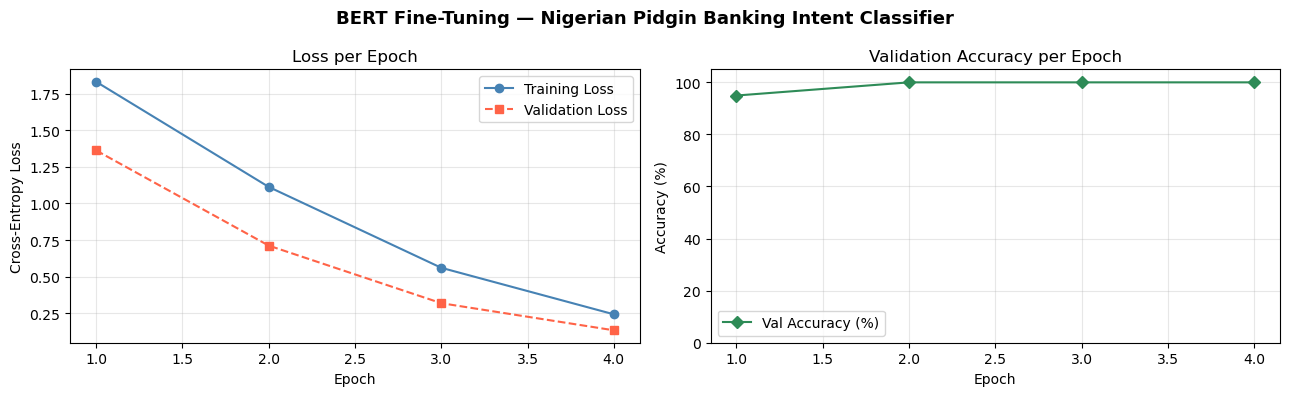

In [22]:
# ============================================================
# CELL 22 — STAGE 6: Training Curves Visualisation
# ============================================================
# Plot training loss, validation loss, and validation accuracy
# across epochs so we can visually confirm the model is learning
# and not overfitting.

import matplotlib.pyplot as plt

epochs_range = training_history['epoch']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('BERT Fine-Tuning — Nigerian Pidgin Banking Intent Classifier',
             fontsize=13, fontweight='bold')

# ── Left plot: Loss curves ────────────────────────────────
axes[0].plot(epochs_range, training_history['train_loss'],
             marker='o', label='Training Loss',   color='steelblue')
axes[0].plot(epochs_range, training_history['val_loss'],
             marker='s', label='Validation Loss', color='tomato',
             linestyle='--')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# ── Right plot: Validation accuracy ──────────────────────
axes[1].plot(epochs_range, training_history['val_accuracy'],
             marker='D', label='Val Accuracy (%)', color='seagreen')
axes[1].set_title('Validation Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim([0, 105])
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [23]:
# ============================================================
# CELL 23 — STAGE 7: Predefined Response Map
# ============================================================
# Because this system uses BERT for intent classification (not
# text generation), we map each (intent, conversation_stage)
# pair to a pre-written Nigerian Pidgin banking response.
#
# conversation_stage values:
#   'initial'   — first turn of a conversation (turn_number == 1)
#   'follow_up' — subsequent turns (turn_number > 1)

RESPONSE_MAP = {
    # ── Balance Inquiry ──────────────────────────────────────
    ('balance_inquiry', 'initial'):
        "Abeg wait small, I go check your account balance for you now now. "
        "Your current balance don dey show for system.",

    ('balance_inquiry', 'follow_up'):
        "I don check again. Your balance still dey same as wetin I tell you before. "
        "You want make I send you statement of account?",

    # ── Failed Transfer ──────────────────────────────────────
    ('failed_transfer', 'initial'):
        "Sorry for the wahala wey that transfer cause you. "
        "I go look am now. Abeg give me the transaction reference number.",

    ('failed_transfer', 'follow_up'):
        "I don see the transfer. E still dey pending processing. "
        "If e no clear within 24 hours, your money go return to your account.",

    # ── ATM Issue ────────────────────────────────────────────
    ('atm_issue', 'initial'):
        "Sorry to hear say the ATM give you problem. "
        "Tell me the ATM location and wetin happen — whether card chop or money no comot.",

    ('atm_issue', 'follow_up'):
        "I don escalate the ATM complaint to our technical team. "
        "If your card dey inside machine, abeg block am now through the app for your safety.",

    # ── Loan Request ─────────────────────────────────────────
    ('loan_request', 'initial'):
        "You wan apply for loan? No wahala. "
        "You qualify for up to ₦500,000 based on your account history. "
        "You want make I start the process?",

    ('loan_request', 'follow_up'):
        "For the loan application, we go need your BVN, six months bank statement, "
        "and one valid ID. You get all these documents ready?",

    # ── Card Issue ───────────────────────────────────────────
    ('card_issue', 'initial'):
        "Sorry about the card issue. Tell me — na your card wey dem decline, "
        "card wey block, or you wan report lost card?",

    ('card_issue', 'follow_up'):
        "I don flag your card issue. If na lost card, I go block am immediately "
        "and request new card for you. New card go reach you within 5-7 working days.",

    # ── Account Opening ──────────────────────────────────────
    ('account_opening', 'initial'):
        "Welcome! You wan open account with us — good choice. "
        "We get savings account, current account, and student account. "
        "Which one you dey consider?",

    ('account_opening', 'follow_up'):
        "To open the account, bring one valid ID (NIN or passport), "
        "one utility bill, and passport photograph to any of our branches. "
        "You fit also start online through our app.",

    # ── Fraud Report ─────────────────────────────────────────
    ('fraud_report', 'initial'):
        "This na serious matter — I dey take am seriously. "
        "I don flag your account for security review immediately. "
        "Abeg describe wetin happen and when you notice the suspicious activity.",

    ('fraud_report', 'follow_up'):
        "I don escalate your fraud report to our security team. "
        "Your account don dey monitored. "
        "You go receive SMS update within the next 2 hours. "
        "No share your OTP or PIN with anybody.",

    # ── Mobile App Issue ─────────────────────────────────────
    ('mobile_app_issue', 'initial'):
        "Sorry say our app dey give you trouble. "
        "Wetin dey happen exactly — e no open, transaction dey fail, "
        "or you see error message?",

    ('mobile_app_issue', 'follow_up'):
        "Try these steps: clear app cache, make sure you get latest version, "
        "then restart your phone. If e still no work, I go reset your app session "
        "from our end right now.",

    # ── Out of Scope ──────────────────────────────────────────
    ('out_of_scope', 'initial'):
        "Sorry o, I no fully understand wetin you talk. "
        "I be your banking assistant, so I fit help you better with things like "
        "account opening, balance check, transfer wahala, card or ATM issues, "
        "loan request, fraud report, or app problems. "
        "Abeg rephrase your question make e relate to one of these.",

    ('out_of_scope', 'follow_up'):
        "I still no understand wetin you dey try to ask. "
        "Make we face bank matter — you fit ask me about your balance, a transfer, "
        "your card, ATM, loan, fraud, account opening, or the mobile app.",
}

print("Response map loaded successfully.")
print(f"Total (intent × stage) response pairs : {len(RESPONSE_MAP)}")


Response map loaded successfully.
Total (intent × stage) response pairs : 16


In [24]:
# ============================================================
# CELL 24 — STAGE 7: Prediction Function
# ============================================================
# predict_intent_and_response() takes:
#   - new_message        : the customer's current Pidgin message
#   - conversation_history: list of previous user messages in this
#                           conversation (empty list for a new chat)
#
# It returns:
#   - predicted intent label (string)
#   - confidence score in % (float)
#   - pre-written Pidgin bot response (string)
#
# Multi-turn context is handled by passing the immediately
# preceding user message as BERT's text_a (context) — the same
# strategy used during training.

import torch
import torch.nn.functional as F

def predict_intent_and_response(new_message, conversation_history=None):
    """
    Predict intent and return a Pidgin bot response.

    Parameters
    ----------
    new_message          : str   — customer's current input message
    conversation_history : list  — previous user messages (oldest first).
                                   Pass [] or None for the first turn.

    Returns
    -------
    tuple: (intent_label, confidence_pct, bot_response)
    """
    if conversation_history is None:
        conversation_history = []

    # ── Step 1: Apply the same cleaning as training data ─────
    cleaned_message = re.sub(r'[^\w\s]', '', str(new_message))
    cleaned_message = re.sub(r'\s+', ' ', cleaned_message).strip().lower()

    # ── Step 2: Build context from conversation history ───────
    # Use the immediately preceding message as context (same as training)
    if len(conversation_history) == 0:
        context = ''
        conversation_stage = 'initial'
    else:
        # Clean the previous message to match training preprocessing
        prev_msg = conversation_history[-1]
        context  = re.sub(r'[^\w\s]', '', str(prev_msg))
        context  = re.sub(r'\s+', ' ', context).strip().lower()
        conversation_stage = 'follow_up'

    # ── Step 3: Tokenize using the same function as training ──
    input_ids, attention_mask = tokenize_conversation_turn(
        context=context, message=cleaned_message, max_length=64
    )

    # ── Step 4: Convert to tensors and move to device ─────────
    input_ids_t      = torch.tensor([input_ids],      dtype=torch.long).to(device)
    attention_mask_t = torch.tensor([attention_mask], dtype=torch.long).to(device)

    # ── Step 5: Run BERT forward pass (no gradient needed) ────
    bert_model.eval()
    with torch.no_grad():
        outputs = bert_model(
            input_ids      = input_ids_t,
            attention_mask = attention_mask_t
        )

    # ── Step 6: Convert logits → probabilities → prediction ───
    probabilities    = F.softmax(outputs.logits, dim=1)
    confidence_score = probabilities.max().item() * 100
    predicted_class  = outputs.logits.argmax(dim=1).item()
    intent_label     = label_encoder.inverse_transform([predicted_class])[0]

    # ── Step 7: Look up the predefined Pidgin response ────────
    response_key = (intent_label, conversation_stage)
    bot_response = RESPONSE_MAP.get(
        response_key,
        "Sorry, I no understand fully. Abeg explain again make I help you better."
    )

    return intent_label, round(confidence_score, 2), bot_response

print("predict_intent_and_response() function defined and ready.")


predict_intent_and_response() function defined and ready.


In [25]:
# ============================================================
# CELL 25 — STAGE 7: Single-Turn Prediction Examples
# ============================================================
# Test the trained model on three isolated Nigerian Pidgin
# messages (no prior conversation context).

single_turn_tests = [
    "Abeg show me my account balance for today",
    "My transfer fail and the money never return — wetin I go do?",
    "I want open new savings account with una bank"
]

print("=" * 65)
print("  SINGLE-TURN PREDICTION EXAMPLES  (No Prior Context)")
print("=" * 65)

for i, test_msg in enumerate(single_turn_tests, 1):
    intent, confidence, response = predict_intent_and_response(
        new_message=test_msg,
        conversation_history=[]    # empty — first turn of a new conversation
    )
    print(f"\n  Test {i}:")
    print(f"  Customer  : \"{test_msg}\"")
    print(f"  Intent    : {intent}  ({confidence}% confidence)")
    print(f"  Bot Reply : {response}")
    print(f"  {'-' * 60}")


  SINGLE-TURN PREDICTION EXAMPLES  (No Prior Context)

  Test 1:
  Customer  : "Abeg show me my account balance for today"
  Intent    : balance_inquiry  (88.83% confidence)
  Bot Reply : Abeg wait small, I go check your account balance for you now now. Your current balance don dey show for system.
  ------------------------------------------------------------

  Test 2:
  Customer  : "My transfer fail and the money never return — wetin I go do?"
  Intent    : failed_transfer  (85.58% confidence)
  Bot Reply : Sorry for the wahala wey that transfer cause you. I go look am now. Abeg give me the transaction reference number.
  ------------------------------------------------------------

  Test 3:
  Customer  : "I want open new savings account with una bank"
  Intent    : account_opening  (86.63% confidence)
  Bot Reply : Welcome! You wan open account with us — good choice. We get savings account, current account, and student account. Which one you dey consider?
  -----------------------

In [26]:
# ============================================================
# CELL 27 — STAGE 7: Multi-Turn Example 2 — Fraud Report
# ============================================================

print("=" * 65)
print("  MULTI-TURN EXAMPLE 2: Fraud Report")
print("=" * 65)

conversation_history_ex2 = []

# ── Turn 1 ───────────────────────────────────────────────────
turn1_msg = "Somebody use my account do transaction wey I no authorise — "  \
            "I think say my account don dey hacked"
intent1, conf1, response1 = predict_intent_and_response(
    new_message=turn1_msg,
    conversation_history=conversation_history_ex2
)
print(f"\n  Turn 1")
print(f"  Customer  : \"{turn1_msg}\"")
print(f"  Intent    : {intent1}  ({conf1}% confidence)  |  Stage: initial")
print(f"  Bot Reply : {response1}")

conversation_history_ex2.append(turn1_msg)

# ── Turn 2 ───────────────────────────────────────────────────
turn2_msg = "The transaction happen this morning, e be like say ₦50,000 comot"
intent2, conf2, response2 = predict_intent_and_response(
    new_message=turn2_msg,
    conversation_history=conversation_history_ex2
)
print(f"\n  Turn 2  (context = Turn 1 message)")
print(f"  Customer  : \"{turn2_msg}\"")
print(f"  Intent    : {intent2}  ({conf2}% confidence)  |  Stage: follow_up")
print(f"  Bot Reply : {response2}")

print(f"\n{'=' * 65}")


  MULTI-TURN EXAMPLE 2: Fraud Report

  Turn 1
  Customer  : "Somebody use my account do transaction wey I no authorise — I think say my account don dey hacked"
  Intent    : fraud_report  (84.31% confidence)  |  Stage: initial
  Bot Reply : This na serious matter — I dey take am seriously. I don flag your account for security review immediately. Abeg describe wetin happen and when you notice the suspicious activity.

  Turn 2  (context = Turn 1 message)
  Customer  : "The transaction happen this morning, e be like say ₦50,000 comot"
  Intent    : fraud_report  (84.54% confidence)  |  Stage: follow_up
  Bot Reply : I don escalate your fraud report to our security team. Your account don dey monitored. You go receive SMS update within the next 2 hours. No share your OTP or PIN with anybody.



In [27]:
# ============================================================
# CELL 28 — STAGE 7: Multi-Turn Example 3 — Mobile App Issue
# ============================================================

print("=" * 65)
print("  MULTI-TURN EXAMPLE 3: Mobile App Issue")
print("=" * 65)

conversation_history_ex3 = []

# ── Turn 1 ───────────────────────────────────────────────────
turn1_msg = "I no fit login to una banking app since yesterday — "  \
            "e dey show error message say my password wrong"
intent1, conf1, response1 = predict_intent_and_response(
    new_message=turn1_msg,
    conversation_history=conversation_history_ex3
)
print(f"\n  Turn 1")
print(f"  Customer  : \"{turn1_msg}\"")
print(f"  Intent    : {intent1}  ({conf1}% confidence)  |  Stage: initial")
print(f"  Bot Reply : {response1}")

conversation_history_ex3.append(turn1_msg)

# ── Turn 2 ───────────────────────────────────────────────────
turn2_msg = "I don try wetin you talk — clear cache and update — " \
            "e still no dey work at all"
intent2, conf2, response2 = predict_intent_and_response(
    new_message=turn2_msg,
    conversation_history=conversation_history_ex3
)
print(f"\n  Turn 2  (context = Turn 1 message)")
print(f"  Customer  : \"{turn2_msg}\"")
print(f"  Intent    : {intent2}  ({conf2}% confidence)  |  Stage: follow_up")
print(f"  Bot Reply : {response2}")

print(f"\n{'=' * 65}")


  MULTI-TURN EXAMPLE 3: Mobile App Issue

  Turn 1
  Customer  : "I no fit login to una banking app since yesterday — e dey show error message say my password wrong"
  Intent    : fraud_report  (55.59% confidence)  |  Stage: initial
  Bot Reply : This na serious matter — I dey take am seriously. I don flag your account for security review immediately. Abeg describe wetin happen and when you notice the suspicious activity.

  Turn 2  (context = Turn 1 message)
  Customer  : "I don try wetin you talk — clear cache and update — e still no dey work at all"
  Intent    : fraud_report  (52.12% confidence)  |  Stage: follow_up
  Bot Reply : I don escalate your fraud report to our security team. Your account don dey monitored. You go receive SMS update within the next 2 hours. No share your OTP or PIN with anybody.



In [28]:
# ============================================================
# CELL 29 — STAGE 7: Full Pipeline Summary
# ============================================================
# Final summary cell — confirms all pipeline stages completed
# and shows the label-to-index mapping used by the model.

import pandas as pd

print("=" * 65)
print("  PIPELINE COMPLETE — FULL SUMMARY")
print("=" * 65)
print()
print("  Project : Automating Customer Service Using NLP")
print("            A Transformer-Based Model for Nigerian Pidgin Language")
print()
print("  ┌─────────────────────────────────────────────────────┐")
print("  │  Stage 1  Raw Conversational Data Acquisition   ✓  │")
print("  │  Stage 2  Conversational Data Cleaning          ✓  │")
print("  │  Stage 3  Conversational Text Preprocessing     ✓  │")
print("  │  Stage 4  Dataset Preparation for Training      ✓  │")
print("  │  Stage 5  BERT Transformer Model Initialisation ✓  │")
print("  │  Stage 6  Transformer Model Training            ✓  │")
print("  │  Stage 7  Multi-Turn Conversation Prediction    ✓  │")
print("  └─────────────────────────────────────────────────────┘")
print()

# Show the encoded label mapping as a tidy DataFrame
label_mapping_df = pd.DataFrame({
    'Encoded Index': list(range(len(label_encoder.classes_))),
    'Intent Label':  list(label_encoder.classes_)
})

print("  Intent Label Encoding Used by the Model:")
print()
print(label_mapping_df.to_string(index=False))
print()
print("  Model   : bert-base-uncased  (fine-tuned)")
print(f"  Device  : {device}")
print(f"  Epochs  : {NUM_EPOCHS}")
print(f"  Classes : {num_intent_labels}")
print()
print("  The notebook ends here.")
print("  No deployment, API, or web interface is included.")
print("=" * 65)


  PIPELINE COMPLETE — FULL SUMMARY

  Project : Automating Customer Service Using NLP
            A Transformer-Based Model for Nigerian Pidgin Language

  ┌─────────────────────────────────────────────────────┐
  │  Stage 1  Raw Conversational Data Acquisition   ✓  │
  │  Stage 2  Conversational Data Cleaning          ✓  │
  │  Stage 3  Conversational Text Preprocessing     ✓  │
  │  Stage 4  Dataset Preparation for Training      ✓  │
  │  Stage 5  BERT Transformer Model Initialisation ✓  │
  │  Stage 6  Transformer Model Training            ✓  │
  │  Stage 7  Multi-Turn Conversation Prediction    ✓  │
  └─────────────────────────────────────────────────────┘

  Intent Label Encoding Used by the Model:

 Encoded Index     Intent Label
             0  account_opening
             1        atm_issue
             2  balance_inquiry
             3       card_issue
             4  failed_transfer
             5     fraud_report
             6     loan_request
             7 mobile_app_issu

In [29]:
# ============================================================
# CELL 30 — STAGE 7: Live Interactive Chat Session
# ============================================================
# Run this cell to start a real conversation with the BERT-
# powered Nigerian Pidgin banking assistant.
#
# - Type your message and press Enter to send it.
# - The bot will predict the intent and reply in Pidgin.
# - The conversation history is preserved across turns so the
#   model has context for every follow-up message you send.
# - Type  'quit'  or  'exit'  to end the session.

print("=" * 60)
print("  NIGERIAN PIDGIN BANKING ASSISTANT — LIVE CHAT")
print("=" * 60)
print("  Type your message below and press Enter.")
print("  Type 'quit' or 'exit' to end the session.")
print("=" * 60)
print()

# Holds all user messages sent so far in this session
live_conversation_history = []

turn_counter = 0

while True:
    # ── Get customer input ────────────────────────────────────
    try:
        user_input = input("You: ").strip()
    except (EOFError, KeyboardInterrupt):
        print("\n\nSession ended.")
        break

    # ── Exit commands ─────────────────────────────────────────
    if user_input.lower() in ('quit', 'exit', 'bye', 'stop'):
        print()
        print("Bot: Thank you for using our banking service. ")
        print("     No wahala — have a good day!")
        print()
        print(f"Session ended after {turn_counter} turn(s).")
        break

    # ── Skip empty input ──────────────────────────────────────
    if user_input == '':
        continue

    turn_counter += 1

    # ── Run prediction ────────────────────────────────────────
    intent, confidence, bot_reply = predict_intent_and_response(
        new_message=user_input,
        conversation_history=live_conversation_history
    )

    # ── Display bot response ──────────────────────────────────
    print(f"Bot: {bot_reply}")
    print(f"     [Intent: {intent}  |  Confidence: {confidence}%]")
    print()

    # ── Append this message to history for next turn context ──
    live_conversation_history.append(user_input)


  NIGERIAN PIDGIN BANKING ASSISTANT — LIVE CHAT
  Type your message below and press Enter.
  Type 'quit' or 'exit' to end the session.



You:  quit



Bot: Thank you for using our banking service. 
     No wahala — have a good day!

Session ended after 0 turn(s).


In [30]:
# ============================================================
# CELL 15 — STAGE 4: Train / Validation Split
# ============================================================
from sklearn.model_selection import train_test_split

train_indices, val_indices = train_test_split(
    range(len(input_ids_tensor)), test_size=0.15, random_state=42,
    stratify=labels_tensor.numpy())

train_input_ids = input_ids_tensor[train_indices]
train_attention_masks = attention_masks_tensor[train_indices]
train_labels = labels_tensor[train_indices]

val_input_ids = input_ids_tensor[val_indices]
val_attention_masks = attention_masks_tensor[val_indices]
val_labels = labels_tensor[val_indices]

print(f"Training samples   : {len(train_indices)}")
print(f"Validation samples : {len(val_indices)}")




Training samples   : 6800
Validation samples : 1200


In [31]:
# ============================================================
# CELL 16 — STAGE 4: Build DataLoaders
# ============================================================
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(train_input_ids, train_attention_masks, train_labels)
val_dataset   = TensorDataset(val_input_ids,   val_attention_masks,   val_labels)

train_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_dataloader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)

print(f"Training batches   : {len(train_dataloader)}")
print(f"Validation batches : {len(val_dataloader)}")



Training batches   : 425
Validation batches : 38


In [32]:
# ============================================================
# NEW CELL — STAGE 8: Build a Genuinely Unseen Test Set
# ============================================================
# The original 8000 rows only contain 9 sentence templates per
# intent (72 total). To measure TRUE generalisation, this cellb
# defines brand-new Pidgin sentences per intent — different
# wording, never seen anywhere in training — for final testing.

unseen_test_examples = [
    # balance_inquiry
    {'intent_label': 'balance_inquiry', 'context': '', 'user_message': 'abeg make i see my account balance'},
    {'intent_label': 'balance_inquiry', 'context': '', 'user_message': 'i wan know how much dey my account'},
    {'intent_label': 'balance_inquiry', 'context': '', 'user_message': 'check my balance for me abeg'},
    {'intent_label': 'balance_inquiry', 'context': '', 'user_message': 'wetin be my current balance'},
    {'intent_label': 'balance_inquiry', 'context': '', 'user_message': 'my account balance dey worry me check am'},
    {'intent_label': 'balance_inquiry', 'context': 'abeg make i see my account balance', 'user_message': 'e don tey o wetin dey happen'},
    {'intent_label': 'balance_inquiry', 'context': 'i wan know how much dey my account', 'user_message': 'i never see the balance you talk about'},
    {'intent_label': 'balance_inquiry', 'context': 'check my balance for me abeg', 'user_message': 'make i know if e don update'},

    # failed_transfer
    {'intent_label': 'failed_transfer', 'context': '', 'user_message': 'i send money but e no land'},
    {'intent_label': 'failed_transfer', 'context': '', 'user_message': 'my account don debit but transfer no complete'},
    {'intent_label': 'failed_transfer', 'context': '', 'user_message': 'the money wey i send no reach the person'},
    {'intent_label': 'failed_transfer', 'context': '', 'user_message': 'transfer wahala dey e never go'},
    {'intent_label': 'failed_transfer', 'context': '', 'user_message': 'una don take my money but transaction never successful'},
    {'intent_label': 'failed_transfer', 'context': 'i send money but e no land', 'user_message': 'the reference number na txn88213'},
    {'intent_label': 'failed_transfer', 'context': 'my account don debit but transfer no complete', 'user_message': 'abeg how long this go take to resolve'},
    {'intent_label': 'failed_transfer', 'context': 'the money wey i send no reach the person', 'user_message': 'e don tey the person never collect am'},

    # atm_issue
    {'intent_label': 'atm_issue', 'context': '', 'user_message': 'i go atm but e no gree work'},
    {'intent_label': 'atm_issue', 'context': '', 'user_message': 'the machine swallow my card'},
    {'intent_label': 'atm_issue', 'context': '', 'user_message': 'atm debit me but no cash comot'},
    {'intent_label': 'atm_issue', 'context': '', 'user_message': 'i fit no withdraw money for the atm'},
    {'intent_label': 'atm_issue', 'context': '', 'user_message': 'atm dey give error message anytime i try'},
    {'intent_label': 'atm_issue', 'context': 'i go atm but e no gree work', 'user_message': 'i don already share the information'},
    {'intent_label': 'atm_issue', 'context': 'the machine swallow my card', 'user_message': 'nothing don change since'},
    {'intent_label': 'atm_issue', 'context': 'atm debit me but no cash comot', 'user_message': 'na lekki branch i dey talk about'},

    # loan_request
    {'intent_label': 'loan_request', 'context': '', 'user_message': 'abeg i wan take loan from una bank'},
    {'intent_label': 'loan_request', 'context': '', 'user_message': 'wetin i go do to get loan'},
    {'intent_label': 'loan_request', 'context': '', 'user_message': 'i need money urgent make i apply for loan'},
    {'intent_label': 'loan_request', 'context': '', 'user_message': 'do una offer personal loans'},
    {'intent_label': 'loan_request', 'context': '', 'user_message': 'how una loan process take work'},
    {'intent_label': 'loan_request', 'context': 'abeg i wan take loan from una bank', 'user_message': 'no response since i apply'},
    {'intent_label': 'loan_request', 'context': 'wetin i go do to get loan', 'user_message': 'the amount wey i need na 150k'},
    {'intent_label': 'loan_request', 'context': 'i need money urgent make i apply for loan', 'user_message': 'i don submit my bvn already'},

    # card_issue
    {'intent_label': 'card_issue', 'context': '', 'user_message': 'my atm card no gree work for any machine'},
    {'intent_label': 'card_issue', 'context': '', 'user_message': 'card dey decline anytime i wan pay'},
    {'intent_label': 'card_issue', 'context': '', 'user_message': 'i lost my card abeg block am sharp sharp'},
    {'intent_label': 'card_issue', 'context': '', 'user_message': 'pos machine no accept my card'},
    {'intent_label': 'card_issue', 'context': '', 'user_message': 'my debit card don stop working'},
    {'intent_label': 'card_issue', 'context': 'my atm card no gree work for any machine', 'user_message': 'make una resolve am quick quick'},
    {'intent_label': 'card_issue', 'context': 'card dey decline anytime i wan pay', 'user_message': 'the issue still dey persist'},
    {'intent_label': 'card_issue', 'context': 'i lost my card abeg block am sharp sharp', 'user_message': 'the last four digits na 7821'},

    # account_opening
    {'intent_label': 'account_opening', 'context': '', 'user_message': 'abeg i wan start banking with una'},
    {'intent_label': 'account_opening', 'context': '', 'user_message': 'how i go do to get account number'},
    {'intent_label': 'account_opening', 'context': '', 'user_message': 'i wan create current account with una bank'},
    {'intent_label': 'account_opening', 'context': '', 'user_message': 'make una help me register account'},
    {'intent_label': 'account_opening', 'context': '', 'user_message': 'i wan be una customer how i go start'},
    {'intent_label': 'account_opening', 'context': 'abeg i wan start banking with una', 'user_message': 'wetin remain make i complete am'},
    {'intent_label': 'account_opening', 'context': 'how i go do to get account number', 'user_message': 'my documents never verify'},
    {'intent_label': 'account_opening', 'context': 'i wan create current account with una bank', 'user_message': 'i still never get response'},

    # fraud_report
    {'intent_label': 'fraud_report', 'context': '', 'user_message': 'somebody don use my account do transaction wey i no do'},
    {'intent_label': 'fraud_report', 'context': '', 'user_message': 'i think say my account don hack'},
    {'intent_label': 'fraud_report', 'context': '', 'user_message': 'strange debit alert enter my phone'},
    {'intent_label': 'fraud_report', 'context': '', 'user_message': 'abeg my account get fraudulent activity'},
    {'intent_label': 'fraud_report', 'context': '', 'user_message': 'person don steal money from my account'},
    {'intent_label': 'fraud_report', 'context': 'somebody don use my account do transaction wey i no do', 'user_message': 'i dey worried say more money fit comot'},
    {'intent_label': 'fraud_report', 'context': 'i think say my account don hack', 'user_message': 'make una secure my account now now'},
    {'intent_label': 'fraud_report', 'context': 'strange debit alert enter my phone', 'user_message': 'the amount wey comot na 75k'},

    # mobile_app_issue
    {'intent_label': 'mobile_app_issue', 'context': '', 'user_message': 'the app dey hang anytime i open am'},
    {'intent_label': 'mobile_app_issue', 'context': '', 'user_message': 'i no fit login to my mobile app'},
    {'intent_label': 'mobile_app_issue', 'context': '', 'user_message': 'una app no dey load at all'},
    {'intent_label': 'mobile_app_issue', 'context': '', 'user_message': 'the app keep showing error'},
    {'intent_label': 'mobile_app_issue', 'context': '', 'user_message': 'mobile app dey too slow to use'},
    {'intent_label': 'mobile_app_issue', 'context': 'the app dey hang anytime i open am', 'user_message': 'i don do everything you suggest'},
    {'intent_label': 'mobile_app_issue', 'context': 'i no fit login to my mobile app', 'user_message': 'the problem never solve'},
    {'intent_label': 'mobile_app_issue', 'context': 'una app no dey load at all', 'user_message': 'e still dey buggy'},

    # out_of_scope
    {'intent_label': 'out_of_scope', 'context': '', 'user_message': 'abeg wetin be the news today'},
    {'intent_label': 'out_of_scope', 'context': '', 'user_message': 'make we talk about football small'},
    {'intent_label': 'out_of_scope', 'context': '', 'user_message': 'you get any good joke for me'},
    {'intent_label': 'out_of_scope', 'context': '', 'user_message': 'how the weather dey your side'},
    {'intent_label': 'out_of_scope', 'context': '', 'user_message': 'wetin be the best food for lagos'},
    {'intent_label': 'out_of_scope', 'context': 'abeg wetin be the news today', 'user_message': 'no wahala just dey gist me'},
    {'intent_label': 'out_of_scope', 'context': 'make we talk about football small', 'user_message': 'i still dey wait for your answer'},
    {'intent_label': 'out_of_scope', 'context': 'you get any good joke for me', 'user_message': 'abeg make i hear am now'},
]

unseen_test_df = pd.DataFrame(unseen_test_examples)
print(f"Total unseen test examples : {len(unseen_test_df)}")
print(f"Examples per intent          : {len(unseen_test_df) // unseen_test_df['intent_label'].nunique()}")
unseen_test_df.head(10)


Total unseen test examples : 64
Examples per intent          : 8


,intent_label,context,user_message
0,balance_inquiry,,abeg make i see my account balance
1,balance_inquiry,,i wan know how much dey my account
2,balance_inquiry,,check my balance for me abeg
3,balance_inquiry,,wetin be my current balance
4,balance_inquiry,,my account balance dey worry me check am
5,balance_inquiry,abeg make i see my account balance,e don tey o wetin dey happen
6,balance_inquiry,i wan know how much dey my account,i never see the balance you talk about
7,balance_inquiry,check my balance for me abeg,make i know if e don update
8,failed_transfer,,i send money but e no land
9,failed_transfer,,my account don debit but transfer no complete


In [33]:
# ============================================================
# STAGE 8: Add Additional Hard / Ambiguous Test Examples
# ============================================================
additional_hard_examples = [
    {'intent_label': 'balance_inquiry',  'context': '', 'user_message': 'i wan know wetin dey my account before i spend'},
    {'intent_label': 'failed_transfer',  'context': '', 'user_message': 'i try send something but e no work'},
    {'intent_label': 'atm_issue',        'context': '', 'user_message': 'the machine for my street no gree cooperate today'},
    {'intent_label': 'loan_request',     'context': '', 'user_message': 'i need extra cash wetin una fit offer me'},
    {'intent_label': 'card_issue',       'context': '', 'user_message': 'anytime i wan use am for shopping e no gree'},
    {'intent_label': 'account_opening',  'context': '', 'user_message': 'i wan start something with una as new customer'},
    {'intent_label': 'fraud_report',     'context': '', 'user_message': 'i see something for my statement wey i no recognize'},
    {'intent_label': 'mobile_app_issue', 'context': '', 'user_message': 'the thing for my phone no dey function well again'},
    {'intent_label': 'out_of_scope', 'context': '', 'user_message': 'abeg who be the best musician for naija right now'},
]

unseen_test_examples = unseen_test_examples + additional_hard_examples
unseen_test_df = pd.DataFrame(unseen_test_examples)

print(f"Total unseen test examples : {len(unseen_test_df)}")


Total unseen test examples : 72


In [34]:
# ============================================================
# NEW CELL — STAGE 8: Clean and Encode the Unseen Test Set
# ============================================================
# Apply the SAME cleaning steps used on the training data so
# the new sentences are processed identically.

unseen_test_df['user_message'] = unseen_test_df['user_message'].apply(clean_text)
unseen_test_df['user_message'] = unseen_test_df['user_message'].apply(normalize_pidgin_text)
unseen_test_df['user_message'] = unseen_test_df['user_message'].str.lower()

unseen_test_df['context'] = unseen_test_df['context'].apply(clean_text)
unseen_test_df['context'] = unseen_test_df['context'].apply(normalize_pidgin_text)
unseen_test_df['context'] = unseen_test_df['context'].str.lower()

# Encode using the SAME label_encoder fitted earlier (do not re-fit)
unseen_test_df['encoded_label'] = label_encoder.transform(unseen_test_df['intent_label'])

unseen_test_df.head(10)


,intent_label,context,user_message,encoded_label
0,balance_inquiry,,abeg make i see my account balance,2
1,balance_inquiry,,i wan know how much dey my account,2
2,balance_inquiry,,check my balance for me abeg,2
3,balance_inquiry,,wetin be my current balance,2
4,balance_inquiry,,my account balance dey worry me check am,2
5,balance_inquiry,abeg make i see my account balance,e don tey o wetin dey happen,2
6,balance_inquiry,i wan know how much dey my account,i never see the balance you talk about,2
7,balance_inquiry,check my balance for me abeg,make i know if e don update,2
8,failed_transfer,,i send money but e no land,4
9,failed_transfer,,my account don debit but transfer no complete,4


In [35]:
# ============================================================
# NEW CELL — STAGE 8: Tokenize the Unseen Test Set
# ============================================================
# Use the SAME tokenize_conversation_turn() function and
# max_length=64 used for the training data.

unseen_input_ids = []
unseen_attention_masks = []

for _, row in unseen_test_df.iterrows():
    input_ids, attention_mask = tokenize_conversation_turn(
        context=row['context'], message=row['user_message'], max_length=64
    )
    unseen_input_ids.append(input_ids)
    unseen_attention_masks.append(attention_mask)

unseen_input_ids_tensor = torch.tensor(unseen_input_ids, dtype=torch.long)
unseen_attention_masks_tensor = torch.tensor(unseen_attention_masks, dtype=torch.long)
unseen_labels_tensor = torch.tensor(unseen_test_df['encoded_label'].tolist(), dtype=torch.long)

print(f"Tokenized {len(unseen_input_ids)} unseen test examples.")



Tokenized 72 unseen test examples.


In [36]:
# ============================================================
# STAGE 8: Build the Unseen Test DataLoader
# ============================================================
unseen_test_dataset = TensorDataset(unseen_input_ids_tensor, unseen_attention_masks_tensor, unseen_labels_tensor)
unseen_test_dataloader = DataLoader(unseen_test_dataset, batch_size=32, shuffle=False)

print(f"Test batches : {len(unseen_test_dataloader)}")
print(f"Test samples : {len(unseen_test_dataset)}")



Test batches : 3
Test samples : 72


In [37]:
# ============================================================
# CELL 31 — STAGE 8: Generate Model Predictions on Test Set
# ============================================================
all_true_labels = []
all_predicted_labels = []

bert_model.eval()
with torch.no_grad():
    for batch in unseen_test_dataloader:
        b_input_ids      = batch[0].to(device)
        b_attention_mask = batch[1].to(device)
        b_labels         = batch[2].to(device)

        outputs = bert_model(input_ids=b_input_ids, attention_mask=b_attention_mask)
        predictions = torch.argmax(outputs.logits, dim=1)

        all_predicted_labels.extend(predictions.cpu().numpy().tolist())
        all_true_labels.extend(b_labels.cpu().numpy().tolist())

print(f"Generated predictions for {len(all_true_labels)} test samples.")


Generated predictions for 72 test samples.


In [38]:
# ============================================================
# ACCURACY EVALUATION (Test Set)
# ============================================================
# Accuracy measures the overall correctness of the model on
# data it has never seen during training or validation.
#
#               Number of Correct Predictions
#   Accuracy = --------------------------------
#                  Total Number of Predictions

from sklearn.metrics import accuracy_score

overall_accuracy = accuracy_score(all_true_labels, all_predicted_labels)

print("=" * 50)
print("  ACCURACY EVALUATION (Test Set)")
print("=" * 50)
print(f"  Test Samples      : {len(all_true_labels)}")
print(f"  Overall Accuracy  : {overall_accuracy * 100:.2f}%")
print("=" * 50)


  ACCURACY EVALUATION (Test Set)
  Test Samples      : 72
  Overall Accuracy  : 73.61%


In [39]:
# ============================================================
# PRECISION EVALUATION (Test Set)
# ============================================================
# Precision measures how many of the messages predicted as a
# given intent were ACTUALLY that intent.
#
#                  True Positives
#   Precision = ---------------------
#               True Positives + False Positives

from sklearn.metrics import precision_score

precision_macro    = precision_score(all_true_labels, all_predicted_labels, average='macro')
precision_weighted = precision_score(all_true_labels, all_predicted_labels, average='weighted')

print("=" * 50)
print("  PRECISION EVALUATION (Test Set)")
print("=" * 50)
print(f"  Macro Precision    : {precision_macro * 100:.2f}%")
print(f"  Weighted Precision : {precision_weighted * 100:.2f}%")
print("=" * 50)


  PRECISION EVALUATION (Test Set)
  Macro Precision    : 77.45%
  Weighted Precision : 77.45%


In [40]:
# ============================================================
# RECALL EVALUATION (Test Set)
# ============================================================
# Recall measures how many of the ACTUAL messages belonging to
# a given intent were correctly identified by the model.
#
#                True Positives
#   Recall = ---------------------
#            True Positives + False Negatives

from sklearn.metrics import recall_score

recall_macro    = recall_score(all_true_labels, all_predicted_labels, average='macro')
recall_weighted = recall_score(all_true_labels, all_predicted_labels, average='weighted')

print("=" * 50)
print("  RECALL EVALUATION (Test Set)")
print("=" * 50)
print(f"  Macro Recall    : {recall_macro * 100:.2f}%")
print(f"  Weighted Recall : {recall_weighted * 100:.2f}%")
print("=" * 50)


  RECALL EVALUATION (Test Set)
  Macro Recall    : 73.61%
  Weighted Recall : 73.61%


In [41]:
# ============================================================
# F1-SCORE EVALUATION (Test Set)
# ============================================================
# F1-score is the harmonic mean of precision and recall — a
# single balanced score for overall classification performance.
#
#                2 x (Precision x Recall)
#   F1-Score = ----------------------------
#                  (Precision + Recall)

from sklearn.metrics import f1_score

f1_macro    = f1_score(all_true_labels, all_predicted_labels, average='macro')
f1_weighted = f1_score(all_true_labels, all_predicted_labels, average='weighted')

print("=" * 50)
print("  F1-SCORE EVALUATION (Test Set)")
print("=" * 50)
print(f"  Macro F1-Score    : {f1_macro * 100:.2f}%")
print(f"  Weighted F1-Score : {f1_weighted * 100:.2f}%")
print("=" * 50)


  F1-SCORE EVALUATION (Test Set)
  Macro F1-Score    : 71.83%
  Weighted F1-Score : 71.83%


In [42]:
# ============================================================
# SUMMARY GRAPH — Overall Test Set Evaluation Metrics
# ============================================================
# Combine accuracy, precision, recall, and F1-score into a
# single bar chart for a quick visual comparison.

import matplotlib.pyplot as plt

overall_metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Precision (Weighted)',
               'Recall (Macro)', 'Recall (Weighted)',
               'F1-Score (Macro)', 'F1-Score (Weighted)'],
    'Score (%)': [
        overall_accuracy * 100,
        precision_macro * 100,
        precision_weighted * 100,
        recall_macro * 100,
        recall_weighted * 100,
        f1_macro * 100,
        f1_weighted * 100
    ]
})
overall_metrics_df['Score (%)'] = overall_metrics_df['Score (%)'].round(2)

# Display the summary table
overall_metrics_df


,Metric,Score (%)
0,Accuracy,73.61
1,Precision (Macro),77.45
2,Precision (Weighted),77.45
3,Recall (Macro),73.61
4,Recall (Weighted),73.61
5,F1-Score (Macro),71.83
6,F1-Score (Weighted),71.83


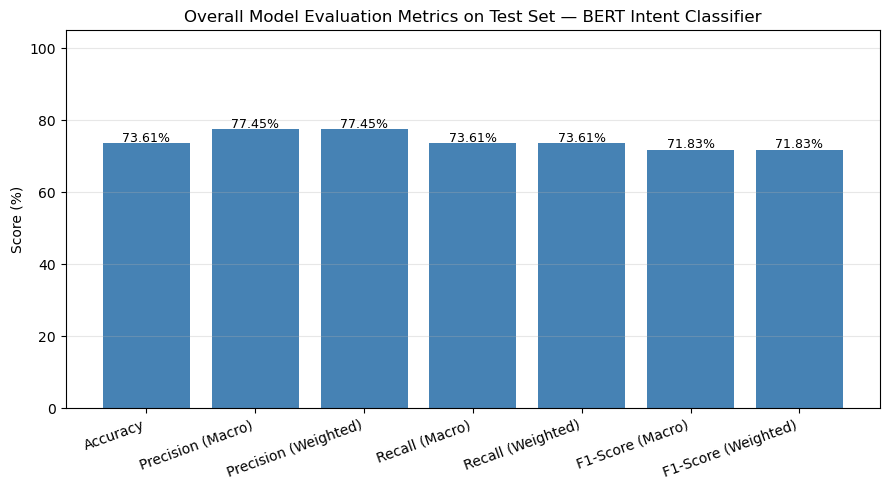

In [43]:
# ── Bar chart of overall test-set evaluation metrics ─────────
plt.figure(figsize=(9, 5))
bars = plt.bar(overall_metrics_df['Metric'], overall_metrics_df['Score (%)'],
               color='steelblue')

for bar, score in zip(bars, overall_metrics_df['Score (%)']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{score}%", ha='center', fontsize=9)

plt.ylim([0, 105])
plt.ylabel('Score (%)')
plt.title('Overall Model Evaluation Metrics on Test Set — BERT Intent Classifier')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [44]:
# ============================================================
# CONFUSION MATRIX ANALYSIS (Test Set)
# ============================================================
# A confusion matrix is an 8x8 table (one row/column per intent)
# that compares actual labels against predicted labels on the
# held-out test set.
#
# - Diagonal cells     = correct predictions
# - Off-diagonal cells = misclassifications

from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(all_true_labels, all_predicted_labels)

# Display as a labelled DataFrame for readability
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=[f"Actual: {name}" for name in label_encoder.classes_],
    columns=[f"Pred: {name}" for name in label_encoder.classes_]
)

conf_matrix_df


,Pred: account_opening,Pred: atm_issue,Pred: balance_inquiry,Pred: card_issue,Pred: failed_transfer,Pred: fraud_report,Pred: loan_request,Pred: mobile_app_issue
Actual: account_opening,3,0,2,0,2,0,0,2
Actual: atm_issue,0,5,0,2,1,1,0,0
Actual: balance_inquiry,0,0,9,0,0,0,0,0
Actual: card_issue,0,1,0,7,0,0,0,1
Actual: failed_transfer,0,0,0,0,9,0,0,0
Actual: fraud_report,0,2,1,0,2,4,0,0
Actual: loan_request,0,1,0,0,0,0,8,0
Actual: mobile_app_issue,0,0,1,0,0,0,0,8


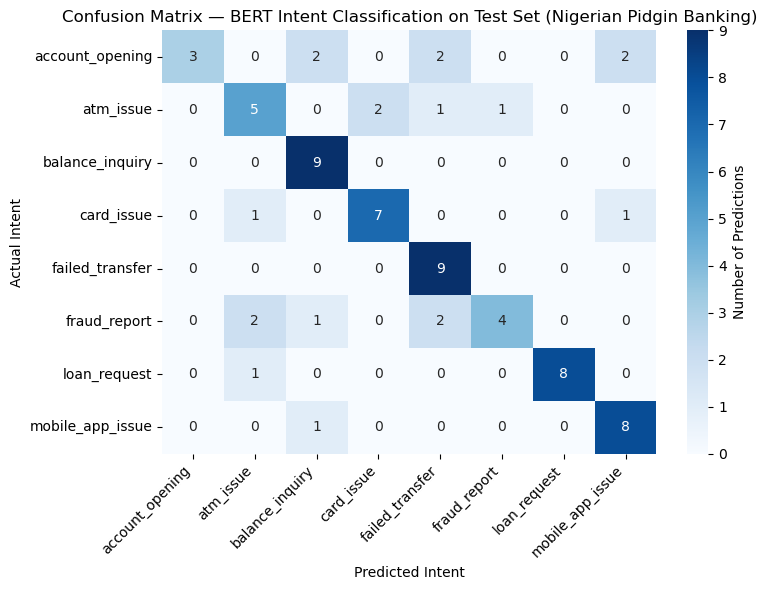

In [45]:
# ── Confusion Matrix Heatmap ─────────────────────────────────
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    cbar_kws={'label': 'Number of Predictions'}
)

plt.xlabel('Predicted Intent')
plt.ylabel('Actual Intent')
plt.title('Confusion Matrix — BERT Intent Classification on Test Set (Nigerian Pidgin Banking)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
